In [1]:
!apt-get -qq install -y tesseract-ocr
%pip install -q pytesseract opencv-python-headless pillow pandas matplotlib "transformers>=4.44,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
#q1
import re
import cv2
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image
from google.colab import files
from transformers import pipeline
from IPython.display import display


def upload_one_image(message):
    print(message)
    uploaded = files.upload()
    image_names = [name for name in uploaded if name.lower().endswith((".png", ".jpg", ".jpeg"))]
    if not image_names:
        raise ValueError("Please upload a JPG or PNG image and run this cell again.")
    return image_names[0]


def read_image_bgr(path):
    image = cv2.imread(path)
    if image is None:
        raise ValueError(f"Unable to open image: {path}")
    return image

print("Libraries imported successfully.")

Libraries imported successfully.


/content/test.png:


Saving test.png to test (2).png


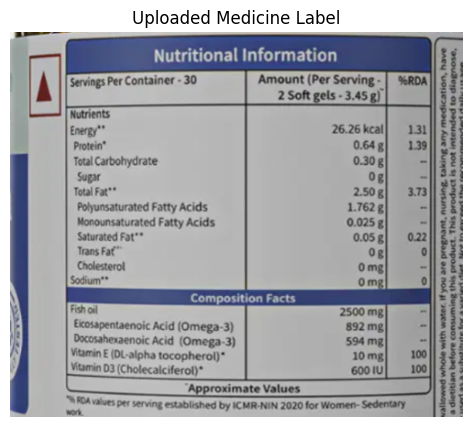

In [6]:
medicine_path = upload_one_image("/content/test.png:")
medicine_image = read_image_bgr(medicine_path)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(medicine_image, cv2.COLOR_BGR2RGB))
plt.title("Uploaded Medicine Label")
plt.axis("off")
plt.show()

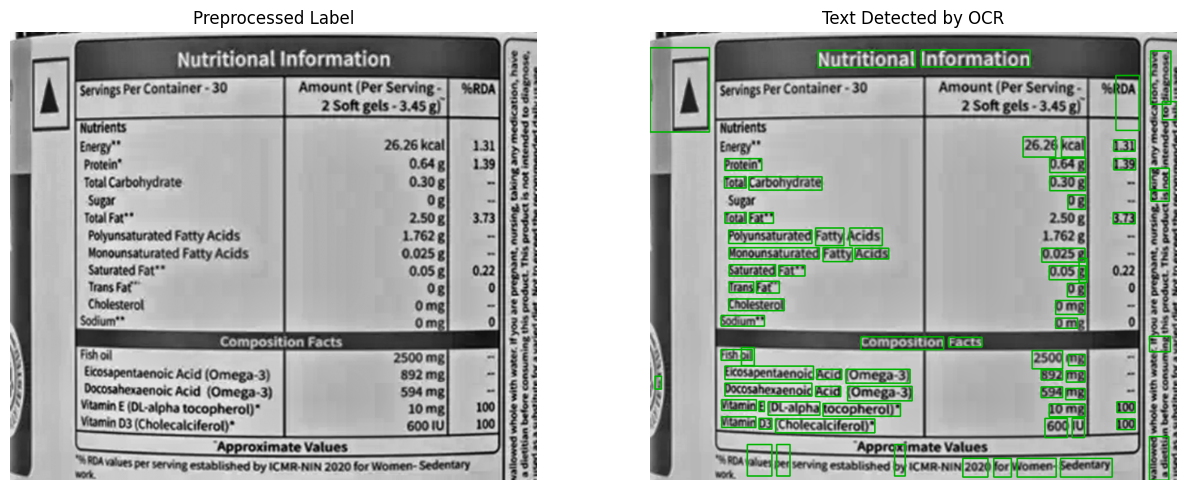

EXTRACTED TEXT:
Nutritional Information
i
|
23
i
26.26 kcal
131
Protein®
139
064g
Total Carbohydrate
0.30g
3
$2
og
Total Fat**
3.73
Polyunsaturated Fatty Acids
Monounsaturated Fatty Acids
0.0258
Saturated Fat"*
Trans Fat”
0.05 g
og
Cholesterol
Omg
Sodium**
om
Composition Facts
<2
Fish oil
2500 mg
Eicosapentaenoic Acid (Omega-3)
892 mg
It
Docosahexaenoic Acid (Omega-3)
594 mg
Vitamin € (OL-alpha tocopherol)*
10mg
100
Vitamin 03 (Cholecaiciferol)*
600 1U
100
dies fur iy 2020 for Women- Sedentary
li

Mean OCR word confidence: 78.3% (approximate)


In [7]:
def preprocess_label(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    scale = min(2.0, 2200 / max(h, w))
    gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(gray)


processed_label = preprocess_label(medicine_image)
ocr_data = pytesseract.image_to_data(
    processed_label,
    config="--oem 3 --psm 11",  # Sparse text: useful for many bottle labels
    output_type=pytesseract.Output.DATAFRAME
)

ocr_data = ocr_data.dropna(subset=["text"]).copy()
ocr_data["text"] = ocr_data["text"].astype(str).str.strip()
ocr_data = ocr_data[(ocr_data["conf"] >= 25) & (ocr_data["text"] != "")]

if not ocr_data.empty:
    line_groups = ocr_data.sort_values(["block_num", "par_num", "line_num", "word_num"])
    ocr_lines = (
        line_groups.groupby(["block_num", "par_num", "line_num"], sort=False)["text"]
        .apply(lambda words: " ".join(words))
        .tolist()
    )
else:
    ocr_lines = []

ocr_text = "\n".join(ocr_lines)

annotated_label = cv2.cvtColor(processed_label, cv2.COLOR_GRAY2BGR)
for _, word in ocr_data.iterrows():
    x, y, w, h = [int(word[k]) for k in ("left", "top", "width", "height")]
    cv2.rectangle(annotated_label, (x, y), (x + w, y + h), (0, 180, 0), 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(processed_label, cmap="gray")
ax[0].set_title("Preprocessed Label")
ax[1].imshow(cv2.cvtColor(annotated_label, cv2.COLOR_BGR2RGB))
ax[1].set_title("Text Detected by OCR")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

print("EXTRACTED TEXT:")
print(ocr_text if ocr_text else "No readable text detected. Please try a clearer photo.")
if not ocr_data.empty:
    print(f"\nMean OCR word confidence: {ocr_data['conf'].mean():.1f}% (approximate)")

In [8]:
def find_labeled_value(lines, pattern):
    for line in lines:
        match = re.search(pattern, line, flags=re.IGNORECASE)
        if match:
            value = match.group(1).strip(" :-./")
            if value:
                return value
    return "Not found"


def extract_medicine_fields(lines):
    text = " ".join(lines)
    strengths = re.findall(r"\b\d+(?:\.\d+)?\s?(?:mg|mcg|g|ml|iu|%)\b", text, flags=re.I)
    unique_strengths = list(dict.fromkeys(strengths))

    skip = ("batch", "exp", "mfg", "manufact", "keep", "store", "warning", "dosage", "ingredients", "contains")
    possible_name = next(
        (line for line in lines if len(line) >= 3 and not line.lower().startswith(skip)),
        "Not found"
    )

    return {
        "Possible product name": possible_name,
        "Strength / volume": ", ".join(unique_strengths) if unique_strengths else "Not found",
        "Batch number": find_labeled_value(lines, r"\b(?:batch|lot|b\.?\s*no\.?)\s*[:#-]?\s*([A-Za-z0-9/-]+)"),
        "Manufacturing date": find_labeled_value(lines, r"\b(?:mfg|mfd|manufactured|manufacturing)\s*(?:date|dt)?\s*[:#-]?\s*([A-Za-z0-9./-]+)"),
        "Expiry date": find_labeled_value(lines, r"\b(?:exp|expiry|expiration|use before|best before)\s*(?:date|dt)?\s*[:#-]?\s*([A-Za-z0-9./-]+)")
    }


medicine_fields = extract_medicine_fields(ocr_lines)
print("MEDICINE LABEL INFORMATION (UNVERIFIED):")
display(pd.DataFrame(medicine_fields.items(), columns=["Field", "OCR Result"]))

print("\nCOGNITIVE ASSISTANT:")
if not ocr_lines:
    print("I could not read this label. Try a sharper photo in brighter light.")
else:
    print("Here is the text and possible label information I could identify.")
    print("Please compare every field with the actual bottle or ask a pharmacist.")
    print("Do NOT use OCR results to decide which medicine to take or what dose to use.")

MEDICINE LABEL INFORMATION (UNVERIFIED):


,Field,OCR Result
0,Possible product name,Nutritional Information
1,Strength / volume,"064g, 0.30g, 0.05 g, 2500 mg, 892 mg, 594 mg, ..."
2,Batch number,Not found
3,Manufacturing date,Not found
4,Expiry date,Not found



COGNITIVE ASSISTANT:
Here is the text and possible label information I could identify.
Please compare every field with the actual bottle or ask a pharmacist.
Do NOT use OCR results to decide which medicine to take or what dose to use.


Upload a face photograph


Saving test.jpg to test (2).jpg


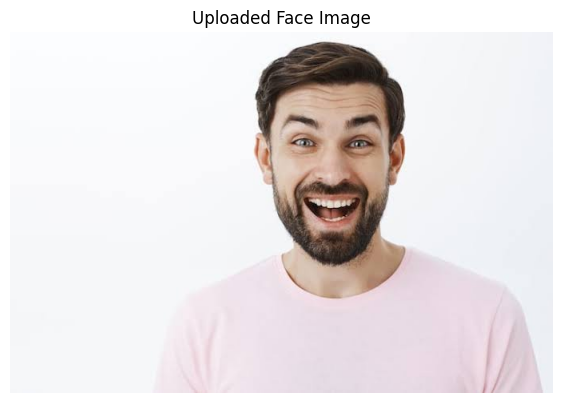

In [16]:
#q2
face_path = upload_one_image("Upload a face photograph")
face_image = read_image_bgr(face_path)

plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(face_image, cv2.COLOR_BGR2RGB))
plt.title("Uploaded Face Image")
plt.axis("off")
plt.show()

In [17]:
MODEL_NAME = "trpakov/vit-face-expression"
device = 0 if torch.cuda.is_available() else -1
emotion_classifier = pipeline(
    task="image-classification",
    model=MODEL_NAME,
    device=device
)

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
if face_detector.empty():
    raise RuntimeError("OpenCV Haar face detector could not be loaded.")

print("Facial-expression classifier loaded.")
print("Running on:", "GPU" if device == 0 else "CPU")

Device set to use cpu


Facial-expression classifier loaded.
Running on: CPU


,Face,Detected expression,Model score
0,1,happy,0.98


Assistant for face 1: I noticed a smiling expression. Would you like to continue?


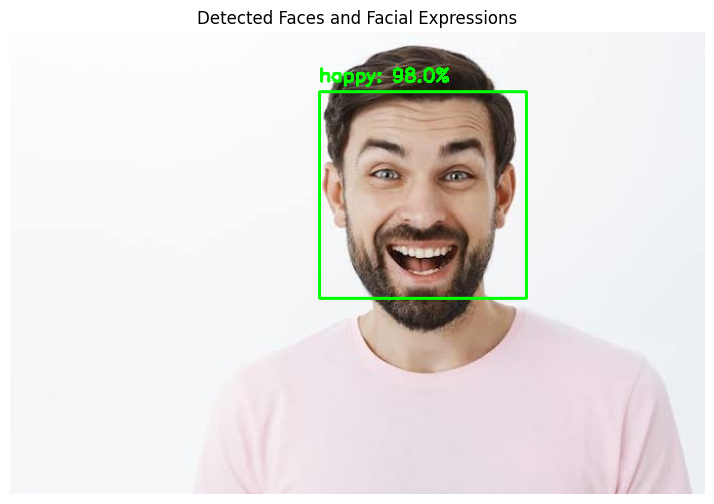

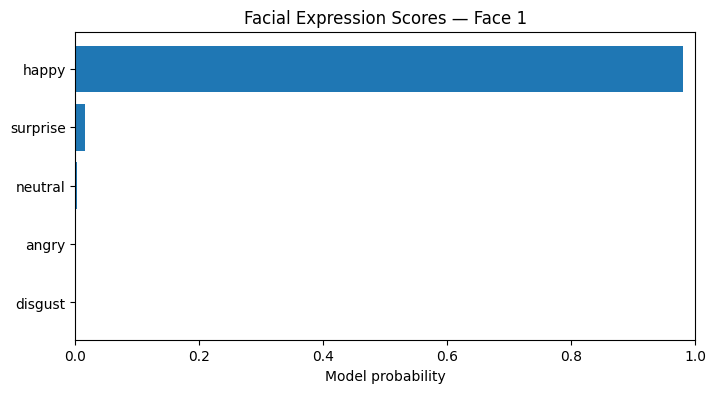

Reminder: Facial expression classification does not reveal someone's actual feelings.


In [18]:
assistant_messages = {
    "happy": "I noticed a smiling expression. Would you like to continue?",
    "sad": "Your expression looks subdued. Would you prefer a slower, gentler pace?",
    "angry": "Your expression seems tense. I can explain things step by step if that helps.",
    "fear": "You look a little uneasy in this image. Would you like a clear explanation?",
    "surprise": "You look surprised in this image! Would you like to know more?",
    "disgust": "Your expression suggests discomfort. Would you like to try a different approach?",
    "neutral": "I see a neutral expression. How can I help you today?"
}

image_rgb = cv2.cvtColor(face_image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(face_image, cv2.COLOR_BGR2GRAY)
faces = face_detector.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(35, 35)
)

output_image = face_image.copy()
face_results = []
all_predictions = []

if len(faces) == 0:
    print("No frontal face detected. Try a clearer, front-facing image with good lighting.")
else:
    for face_number, (x, y, w, h) in enumerate(faces, start=1):
        pad = int(0.15 * max(w, h))
        x1, y1 = max(0, x - pad), max(0, y - pad)
        x2, y2 = min(face_image.shape[1], x + w + pad), min(face_image.shape[0], y + h + pad)
        face_crop = Image.fromarray(image_rgb[y1:y2, x1:x2])

        predictions = emotion_classifier(face_crop, top_k=None)
        predictions = sorted(predictions, key=lambda item: item["score"], reverse=True)
        predicted_expression = predictions[0]["label"].lower()
        confidence = float(predictions[0]["score"])

        face_results.append({
            "Face": face_number,
            "Detected expression": predicted_expression,
            "Model score": round(confidence, 3)
        })
        all_predictions.append(predictions)

        cv2.rectangle(output_image, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(
            output_image, f"{predicted_expression}: {confidence:.1%}",
            (x, max(25, y - 10)), cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (0, 255, 0), 2
        )

    display(pd.DataFrame(face_results))
    for result in face_results:
        expression = result["Detected expression"]
        print(f"Assistant for face {result['Face']}: {assistant_messages[expression]}")

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Faces and Facial Expressions")
plt.axis("off")
plt.show()

# Show expression scores for the first detected face
if all_predictions:
    first_face_scores = pd.DataFrame(all_predictions[0])
    first_face_scores = first_face_scores.sort_values("score", ascending=True)
    plt.figure(figsize=(8, 4))
    plt.barh(first_face_scores["label"], first_face_scores["score"])
    plt.xlabel("Model probability")
    plt.title("Facial Expression Scores — Face 1")
    plt.xlim(0, 1)
    plt.show()

print("Reminder: Facial expression classification does not reveal someone's actual feelings.")